# Camera Pose Calibration From SiPMs

Recovers each camera's real-world pose independent of LAr10Ana's bubble triangulation, by
rendering light sources at the SiPMs' actual 3D positions and
comparing against what the assumed pose (`PoseMatrixEstimation.ipynb`'s
`outputs/estimated_pose_matrices/*.npy`) predicts a real camera would see there.

In [1]:
import os, sys, json, functools
if not os.path.isdir("modules"):
    os.chdir("..")
sys.path.insert(0, "modules")

from utils import *
import pose_calibration as lc
import real_data_loading as rdl

# Cosmetic only: silences Mitsuba's PLYMesh warning about the distorted-jar meshes'
# unused "edge" element (not needed for rendering, from blender).
# Keeps Error-level messages, so real problems still surface.
mi.set_log_level(mi.LogLevel.Error)
# Every figure and render this notebook makes goes into one folder per run:
#   outputs/poseSolve/<date ran>/figures/NN_<name>.png   -- the plots shown inline, in notebook order
#   outputs/poseSolve/<date ran>/renders/<pose>/...png   -- the raw Mitsuba renders behind them
poseSolveDir = lc.new_run_dir()
print("saving this run's images to", poseSolveDir)
save_figure = functools.partial(lc.save_figure, runDir=poseSolveDir)
save_render = functools.partial(lc.save_render, runDir=poseSolveDir)

saving this run's images to outputs/poseSolve/2026_11_16_10_15_26


In [2]:
positions = lc.load_sipm_fiducial_positions()

print(f"{len(positions['fiducial'])} fiducial markers, {len(positions['sipm'])} SiPMs")
for markerId, pos in positions["fiducial"].items():
    print(f"  fiducial {markerId}: {pos} cm")

5 fiducial markers, 48 SiPMs
  fiducial 1: [-5.30300001  2.23937179  0.        ] cm
  fiducial 2: [-2.23817626  5.30375772  0.        ] cm
  fiducial 3: [ 5.30300001 -2.23937179  0.        ] cm
  fiducial 4: [ 2.23817626 -5.30375772  0.        ] cm
  fiducial 5: [0. 0. 0.] cm


In [3]:
camera = 2

## Rendering light sources at the actual SiPM positions

Instead of trying to detect SiPM covers or fiducial markers in a real photo,
place a small light source at each SiPM's *actual* 3D position and render the scene for real.
This shows what the camera would really see there -- whether each one is directly visible, hidden behind the copper
panel, or (like the LED rings) only visible via reflection off the curved dome -- since
it's an actual physically-traced render of this scene's real geometry, not a flat 2D
projection.

saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_assumed_pose/all_sipms_lit.png


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/01_cam2_assumed_pose_all_sipms_lit.png


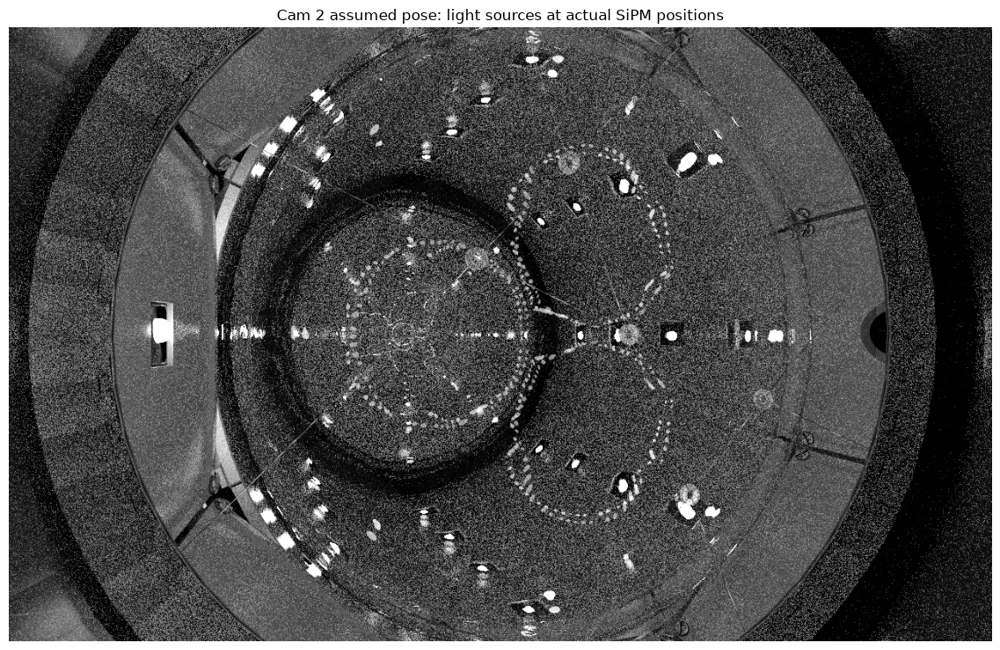

In [4]:
lightMaterials = create_materials(with_fluids=True)
lightComponents = load_components(materials=lightMaterials, use_distorted_jar=True)
lc.add_point_light_markers(lightComponents, positions["sipm"])

lightSensor = create_sensor(sensor_number=camera, sample_count=512)
lightScene = load_scene(components=lightComponents, sensor=lightSensor)
sipmLightImage = to_mono(np.array(render(scene=lightScene, denoise=False)))

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(np.clip(sipmLightImage, 0, 1) ** (1 / 2.2), cmap='gray')
ax.set_title(f"Cam {camera} assumed pose: light sources at actual SiPM positions")
ax.axis('off')
fig.tight_layout()

save_render(sipmLightImage, f"cam{camera}_assumed_pose/all_sipms_lit")
save_figure(fig, f"01_cam{camera}_assumed_pose_all_sipms_lit")

saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_assumed_pose/baseline_no_markers.png


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/02_cam2_assumed_pose_baseline.png


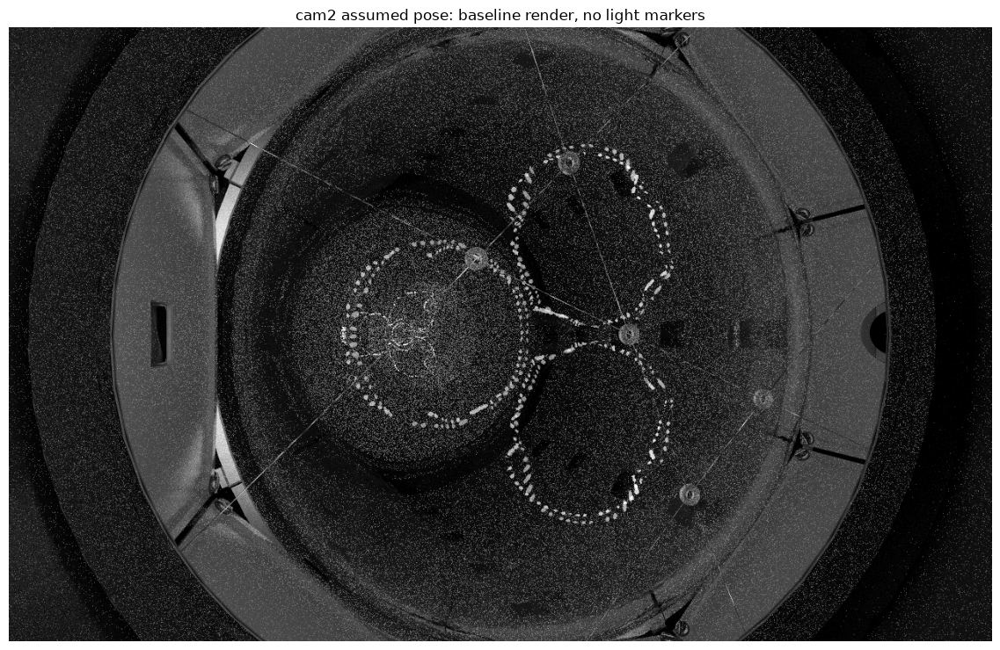

In [5]:
# Same scene/sensor, just no SiPM lights to act as a background to subtract from.
baselineMaterials = create_materials(with_fluids=True)
baselineComponents = load_components(materials=baselineMaterials, use_distorted_jar=True)
baselineSensor = create_sensor(sensor_number=camera, sample_count=512)
baselineScene = load_scene(components=baselineComponents, sensor=baselineSensor)
baselineImage = to_mono(np.array(render(scene=baselineScene, denoise=False)))

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(np.clip(baselineImage, 0, 1) ** (1 / 2.2), cmap='gray')
ax.set_title(f"cam{camera} assumed pose: baseline render, no light markers")
ax.axis('off')
fig.tight_layout()
save_render(baselineImage, f"cam{camera}_assumed_pose/baseline_no_markers")
save_figure(fig, f"02_cam{camera}_assumed_pose_baseline")

## Finding the rendered light sources

Now try to find those same light markers back out of the render itself, with
`detect_light_markers()` -- the same question a detector will eventually have to
answer for a *real* photo, but here against a render where the ground truth (there
should be one blob per SiPM, right where `add_point_light_markers()` put it) is known,
so it's a sanity check on the detector itself before pointing it at real data.

found 36 candidate light markers (expected up to 48)


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/03_cam2_detected_light_markers.png


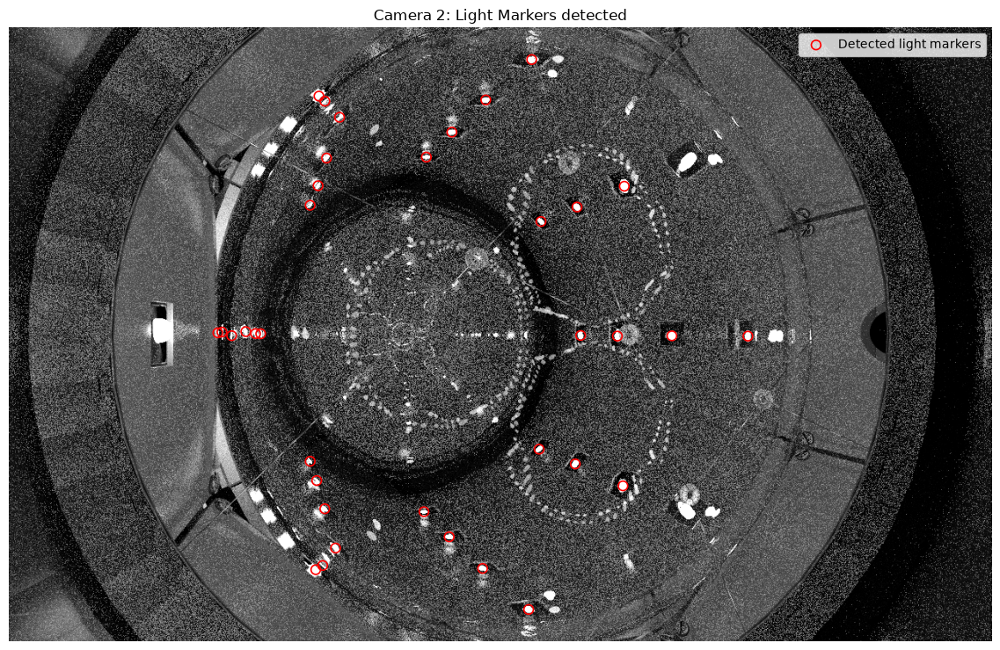

In [6]:
detectedPixels = lc.detect_light_markers(sipmLightImage, baseline=baselineImage)
print(f"found {len(detectedPixels)} candidate light markers "
      f"(expected up to {len(positions['sipm'])})")

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(np.clip(sipmLightImage, 0, 1) ** (1 / 2.2), cmap='gray')
ax.scatter(detectedPixels[:, 0], detectedPixels[:, 1], s=60, facecolors='none',
           edgecolors='red', linewidths=1.2, label='Detected light markers')
ax.legend(loc='upper right')
ax.set_title(f"Camera {camera}: Light Markers detected")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"03_cam{camera}_detected_light_markers")

## Comparing against a real photo

`project_positions_to_pixels()`'s flat projection isn't refraction-aware -- checked:
diffing a single-marker render against a no-marker baseline showed the marker's actual
rendered pixel drifting 15-70px from that flat projection, growing with distance from the
image center, and dropping to ~5px once removing the liquid argon (no refraction) is
tested instead. So the flat projection isn't a reliable stand-in for where a real photo
would show a SiPM either, and matching against it (as an earlier version of this notebook
did) mostly just checks that detection and projection math agree with each other, not
that the assumed pose matches reality.

`detectedPixels` (above) doesn't have that problem -- it comes from an actual ray-traced
render, so refraction through the jar/fluid is already correctly baked in for the
*assumed* pose. The real test of whether that assumed pose matches the *real* camera is
whether those same pixel positions line up with a real photo from the same camera: if the
assumed pose is right, wherever a SiPM shows up in the render should land close to where it
actually shows up in reality. No real-photo SiPM detector is trusted yet (see
`detect_sipm_covers()`'s own docstring), so for now this is a visual overlay rather than an
automated match.

saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/04_cam2_real_photo_vs_assumed_render.png


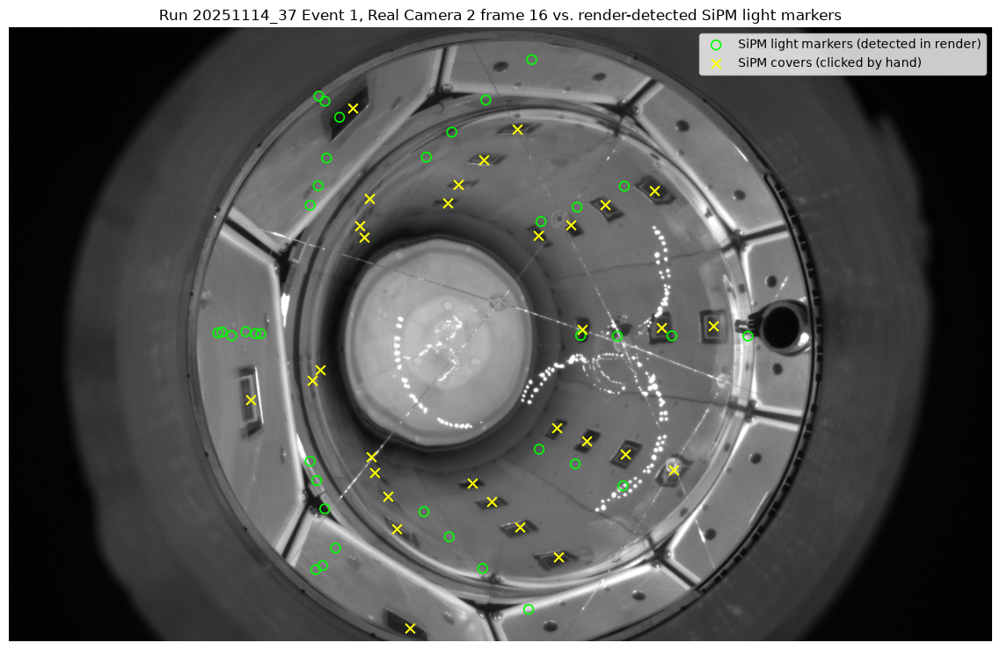

In [7]:
run_name = "20251114_37"
run_dir = rdl.RUN_DIRS[run_name]
ev = rdl.single_bubble_events(run_dir)[0]
frame = 16

realImage = load_image(rdl.camera_image_path(run_dir, ev, camera, frame))

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(detectedPixels[:, 0], detectedPixels[:, 1], s=60, facecolors='none',
           edgecolors='lime', linewidths=1.2,
           label='SiPM light markers (detected in render)')

# Overlay clicked points (scripts/click_label_points.py), if you've made any,
# for a direct by-eye comparison against the render-detected positions above.
clickedPointsPath = "outputs/clicked_points/cam2-img16_sorted.json"
if os.path.exists(clickedPointsPath):
    clickedPixels = lc.load_clicked_points(clickedPointsPath)
    ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
               linewidths=1.5, label='SiPM covers (clicked by hand)')
else:
    print(f"no clicked points found at {clickedPointsPath} -- run "
          f"scripts/click_label_points.py to add some")

ax.legend(loc='upper right')
ax.set_title(f"Run {run_name} Event {ev}, Real Camera {camera} frame {frame} "
             f"vs. render-detected SiPM light markers")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"04_cam{camera}_real_photo_vs_assumed_render")

## Labeling each visible SiPM's true render position

To match your clicked covers (`scripts/click_label_points.py`) to a specific SiPM id,
we need an id-labeled *render* position for each one -- not `project_positions_to_pixels()`
(refraction-biased by tens of pixels) and not `detectedPixels` above
(all 48 lit at once, so close-together SiPMs like ring 4's can merge into one blob).

Instead this renders each SiPM's marker **alone** and diffs against the same
`baselineImage` from above -- the same approach that pinned down SiPM 46 earlier, just
run for every id. A higher radiance (200 vs. the usual 80) keeps the peak unambiguous
even at a modest sample count. Slow -- one full render per SiPM, ~15-20s each, so
~48 x that -- and prints progress as it goes. Anything whose peak diff stays near noise
level (<10, same cutoff `detect_light_markers()` uses) isn't directly visible from this
camera and gets skipped, same as the occluded ones we already found by ring.

In [8]:
# Cached: this loop is ~12-15 min. Delete the cache file to force a re-render (only a
# re-render saves the 48 single-SiPM renders into this run's renders/ folder).
sipmRenderPositionsPath = f"outputs/pose_calibration/cam{camera}_sipm_render_positions.json"

if os.path.exists(sipmRenderPositionsPath):
    with open(sipmRenderPositionsPath) as f:
        sipmRenderPositions = {sid: np.array(xy) for sid, xy in json.load(f).items()}
    print(f"loaded {len(sipmRenderPositions)} cached SiPM render positions from {sipmRenderPositionsPath}")
else:
    sipmRenderPositions = {}
    visibilityThreshold = 10.0

    for i, (sid, pos) in enumerate(positions["sipm"].items()):
        perIdMaterials = create_materials(with_fluids=True)
        perIdComponents = load_components(materials=perIdMaterials, use_distorted_jar=True)
        lc.add_point_light_markers(perIdComponents, {sid: pos}, radiance=200.0)
        perIdSensor = create_sensor(sensor_number=camera, sample_count=64)
        perIdScene = load_scene(components=perIdComponents, sensor=perIdSensor)
        perIdImage = to_mono(np.array(render(scene=perIdScene, denoise=False)))

        diff = perIdImage - baselineImage
        save_render(perIdImage, f"cam{camera}_assumed_pose/single_sipm/sipm_{sid}")
        save_render(diff, f"cam{camera}_assumed_pose/single_sipm/sipm_{sid}_diff", isDiff=True)
        maxDiff = diff.max()
        yx = np.unravel_index(np.argmax(diff), diff.shape)
        peak = np.array([yx[1], yx[0]])
        visible = maxDiff >= visibilityThreshold
        if visible:
            sipmRenderPositions[sid] = peak

        status = "" if visible else " (not visible, skipped)"
        print(f"[{i + 1}/{len(positions['sipm'])}] sipm {sid}: maxDiff={maxDiff:.1f} "
              f"peak={tuple(peak)}{status}")

    print(f"\n{len(sipmRenderPositions)}/{len(positions['sipm'])} SiPMs visible from cam{camera}")

    os.makedirs(os.path.dirname(sipmRenderPositionsPath), exist_ok=True)
    with open(sipmRenderPositionsPath, "w") as f:
        json.dump({sid: [int(v) for v in xy] for sid, xy in sipmRenderPositions.items()}, f, indent=1)

loaded 36 cached SiPM render positions from outputs/pose_calibration/cam2_sipm_render_positions.json


### Example: one single-SiPM render

The loop above only keeps each id's peak pixel and discards the actual image (48 full
renders would be a lot of memory to hold onto at once). Here's what one of those
individual renders -- and the diff that finds its peak -- actually looks like, using
SiPM 46 (the one we already identified as the rectangular cover earlier in this
notebook) as the example.

SiPM 46: maxDiff=126.2, peak=(209, 396)


saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_assumed_pose/single_sipm/sipm_46.png
saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_assumed_pose/single_sipm/sipm_46_diff.png


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/05_cam2_single_sipm_46_example.png


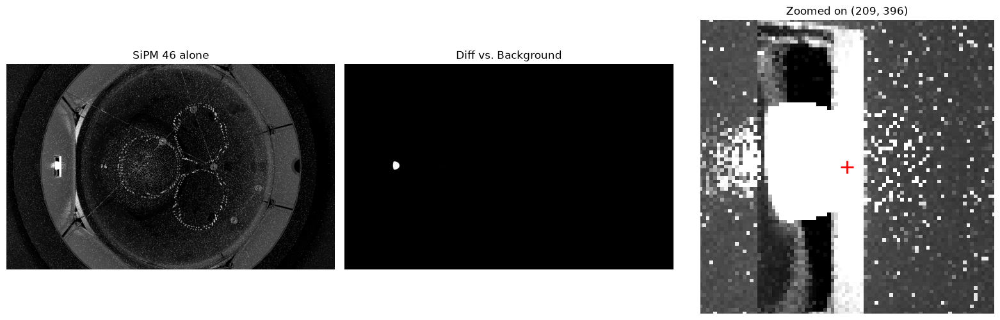

In [9]:
exampleId = "46"

exampleMaterials = create_materials(with_fluids=True)
exampleComponents = load_components(materials=exampleMaterials, use_distorted_jar=True)
lc.add_point_light_markers(exampleComponents, {exampleId: positions["sipm"][exampleId]}, radiance=200.0)
exampleSensor = create_sensor(sensor_number=camera, sample_count=64)
exampleScene = load_scene(components=exampleComponents, sensor=exampleSensor)
exampleImage = to_mono(np.array(render(scene=exampleScene, denoise=False)))

exampleDiff = exampleImage - baselineImage
yx = np.unravel_index(np.argmax(exampleDiff), exampleDiff.shape)
examplePeak = (int(yx[1]), int(yx[0]))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(np.clip(exampleImage, 0, 1) ** (1 / 2.2), cmap='gray')
axes[0].set_title(f"SiPM {exampleId} alone")
axes[1].imshow(exampleDiff, cmap='gray', vmin=0, vmax=exampleDiff.max())
axes[1].set_title("Diff vs. Background")
win = 40
x0, x1 = max(examplePeak[0] - win, 0), examplePeak[0] + win
y0, y1 = max(examplePeak[1] - win, 0), examplePeak[1] + win
axes[2].imshow(np.clip(exampleImage, 0, 1) ** (1 / 2.2), cmap='gray')
axes[2].plot(*examplePeak, '+', color='red', markersize=15, markeredgewidth=2)
axes[2].set_xlim(x0, x1)
axes[2].set_ylim(y1, y0)
axes[2].set_title(f"Zoomed on {examplePeak}")
for ax in axes:
    ax.axis('off')
fig.tight_layout()
print(f"SiPM {exampleId}: maxDiff={exampleDiff.max():.1f}, peak={examplePeak}")
save_render(exampleImage, f"cam{camera}_assumed_pose/single_sipm/sipm_{exampleId}")
save_render(exampleDiff, f"cam{camera}_assumed_pose/single_sipm/sipm_{exampleId}_diff", isDiff=True)
save_figure(fig, f"05_cam{camera}_single_sipm_{exampleId}_example")

## Matching manually found covers to SiPM ids

Nearest-neighbor match each clicked point against `sipmRenderPositions` above (id-labeled,
refraction-correct render positions) within `maxMatchDistancePx`. Reports which id each
click matched to, and flags anything left over on either side.

matched 4/31 clicked points to a SiPM id (within 30px)
  click 15 ([848.9 390.6]) -> sipm 84, 21.1px away
  click 16 ([745.6 393.4]) -> sipm 82, 5.7px away
  click 18 ([730.6 256.4]) -> sipm 73, 24.8px away
  click 19 ([689.1 270. ]) -> sipm 72, 21.1px away

27 clicked point(s) didn't match any visible SiPM: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 17, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/06_cam2_clicks_nearest_neighbor_matches.png


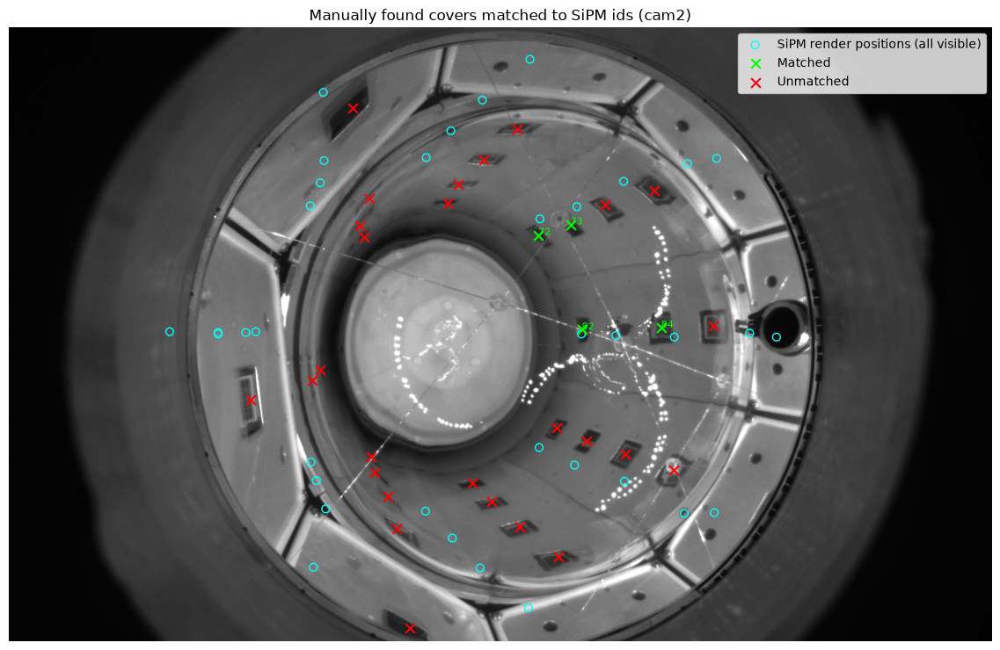

In [10]:
clickedPointsPath = "outputs/clicked_points/cam2-img16_sorted.json"
maxMatchDistancePx = 30

if not os.path.exists(clickedPointsPath):
    print(f"no clicked points found at {clickedPointsPath}")
else:
    clickedPixels = lc.load_clicked_points(clickedPointsPath)
    sipmIds = list(sipmRenderPositions.keys())
    sipmXY = np.array(list(sipmRenderPositions.values()))

    matches = []
    for i, click in enumerate(clickedPixels):
        distances = np.linalg.norm(sipmXY - click, axis=1)
        nearest = distances.argmin()
        if distances[nearest] <= maxMatchDistancePx:
            matches.append((i, sipmIds[nearest], distances[nearest]))
    matchedClickIndices = {m[0] for m in matches}

    print(f"matched {len(matches)}/{len(clickedPixels)} clicked points to a SiPM id "
          f"(within {maxMatchDistancePx}px)")
    for i, sid, dist in matches:
        print(f"  click {i} ({clickedPixels[i].round(1)}) -> sipm {sid}, {dist:.1f}px away")

    unmatchedClicks = [i for i in range(len(clickedPixels)) if i not in matchedClickIndices]
    if unmatchedClicks:
        print(f"\n{len(unmatchedClicks)} clicked point(s) didn't match any visible SiPM: "
              f"{unmatchedClicks}")

    realImage = load_image(rdl.camera_image_path(run_dir, ev, camera, frame))
    fig, ax = plt.subplots(figsize=(12, 7.5))
    ax.imshow(realImage, cmap='gray')
    ax.scatter(sipmXY[:, 0], sipmXY[:, 1], s=40, facecolors='none', edgecolors='cyan',
               linewidths=1, label='SiPM render positions (all visible)')
    if matchedClickIndices:
        matchedXY = clickedPixels[list(matchedClickIndices)]
        ax.scatter(matchedXY[:, 0], matchedXY[:, 1], s=60, marker='x', color='lime',
                   linewidths=1.5, label='Matched')
    if unmatchedClicks:
        unmatchedXY = clickedPixels[unmatchedClicks]
        ax.scatter(unmatchedXY[:, 0], unmatchedXY[:, 1], s=60, marker='x', color='red',
                   linewidths=1.5, label='Unmatched')
    for i, sid, dist in matches:
        ax.annotate(sid, clickedPixels[i], color='lime', fontsize=8)
    ax.legend(loc='upper right')
    ax.set_title(f"Manually found covers matched to SiPM ids (cam{camera})")
    ax.axis('off')
    fig.tight_layout()
    save_figure(fig, f"06_cam{camera}_clicks_nearest_neighbor_matches")

## Visualizing the offset

For every clicked cover, draw an arrow to its *nearest* SiPM render position --
regardless of `maxMatchDistancePx` -- so the direction and size of the mismatch is
visible even for clicks that didn't technically "match". Green arrows are within the
cutoff (same as the matches above); red arrows are the rest, and their length is a
direct read on how far off the assumed pose is at that point in the frame.

nearest-SiPM distance per click: min=5.7px median=59.0px max=120.7px


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/07_cam2_click_offsets_assumed_pose.png


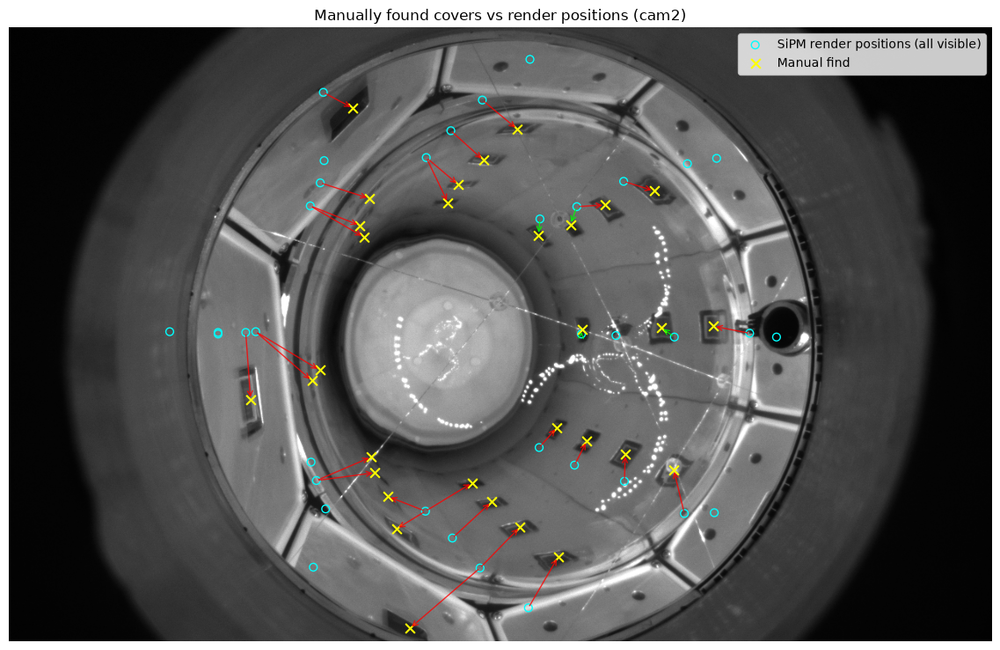

In [11]:
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(sipmXY[:, 0], sipmXY[:, 1], s=40, facecolors='none', edgecolors='cyan',
           linewidths=1, label='SiPM render positions (all visible)')
ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
           linewidths=1.5, label='Manual find')

offsetDistances = []
for click in clickedPixels:
    distances = np.linalg.norm(sipmXY - click, axis=1)
    nearest = distances.argmin()
    offsetDistances.append(distances[nearest])
    color = 'lime' if distances[nearest] <= maxMatchDistancePx else 'red'
    ax.annotate('', xy=sipmXY[nearest], xytext=click,
                arrowprops=dict(arrowstyle='<-', color=color, linewidth=1, alpha=0.8))

offsetDistances = np.array(offsetDistances)
print(f"nearest-SiPM distance per click: min={offsetDistances.min():.1f}px "
      f"median={np.median(offsetDistances):.1f}px max={offsetDistances.max():.1f}px")

ax.legend(loc='upper right')
ax.set_title(f"Manually found covers vs render positions (cam{camera})")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"07_cam{camera}_click_offsets_assumed_pose")

## Solving for the real pose

The arrows above are far too long and too consistent in direction to be noise: the
assumed pose itself is off. `lc.fit_pose_correction()` solves for the correction:

- **Refraction**: each SiPM's refraction offset is measured once from its own
  render (`sipmRenderPositions` minus the flat projection) and assumed to stay fixed
  for a small pose change. Prediction = flat projection at the corrected pose + offset.
- **Correspondence**: ICP-style. Match clicks to predictions one-to-one within a
  cutoff, fit, shrink the cutoff (130 -> 90 -> 60 -> 40px), and repeat.
- **Rotation only** (camera pivots about its own center). Also solving for translation
  fit the clicks better on paper, but it did so with a 2-3cm camera shift. A render at
  that pose put the camera inside the viewport geometry, and only 14 of 36 SiPMs stayed
  visible. So the extra freedom was absorbing something the flat model leaves out
  (most likely lens distortion or fov), not a real offset.

In [12]:
sipmIds = list(sipmRenderPositions.keys())
assumedToWorld = np.array(create_sensor(sensor_number=camera)["to_world"].matrix)

poseFit = lc.fit_pose_correction(
    worldPositionsCm=[positions["sipm"][sid] for sid in sipmIds],
    renderPixels=[sipmRenderPositions[sid] for sid in sipmIds],
    observedPixels=clickedPixels,
    toWorld=assumedToWorld,
)
correctedToWorld = poseFit["toWorld"]

rotationDeg = np.rad2deg(poseFit["correction"][:3])
print(f"cam{camera} rotation correction (camera frame, Rodrigues): {rotationDeg.round(2)} deg "
      f"-> {np.linalg.norm(rotationDeg):.2f} deg total")
print(f"matched {len(poseFit['pairs'])}/{len(clickedPixels)} clicks one-to-one; predicted residual "
      f"median {np.median(poseFit['residualsPx']):.1f}px, max {poseFit['residualsPx'].max():.1f}px "
      f"(was {np.median(offsetDistances):.1f}px median before)")
print("matched SiPM ids:", sorted(sipmIds[p] for p, _ in poseFit["pairs"]))

cam2 rotation correction (camera frame, Rodrigues): [-0.93  5.1   6.73] deg -> 8.49 deg total
matched 23/31 clicks one-to-one; predicted residual median 18.6px, max 29.5px (was 59.0px median before)
matched SiPM ids: ['12', '13', '14', '22', '23', '24', '32', '33', '34', '44', '45', '52', '53', '54', '55', '62', '63', '64', '72', '73', '74', '83', '84']


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/08_cam2_corrected_pose_prediction.png


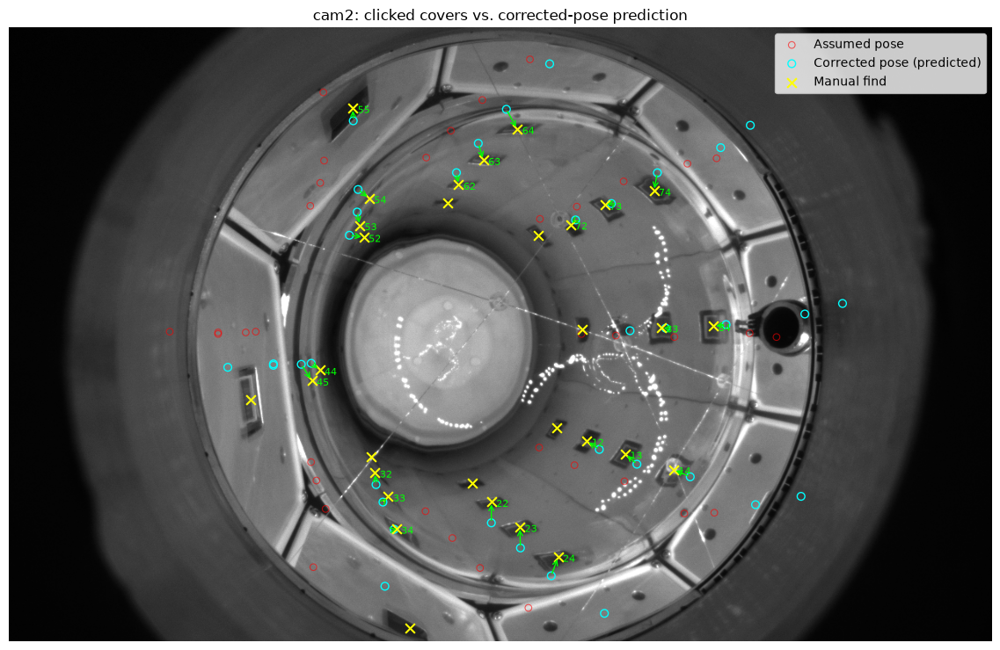

In [13]:
predictedPixels = (lc.flat_project(correctedToWorld, [positions["sipm"][sid] for sid in sipmIds])
                   + poseFit["deltaPx"])

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(sipmXY[:, 0], sipmXY[:, 1], s=30, facecolors='none', edgecolors='red', linewidths=0.8,
           alpha=0.6, label='Assumed pose')
ax.scatter(predictedPixels[:, 0], predictedPixels[:, 1], s=40, facecolors='none', edgecolors='cyan',
           linewidths=1, label='Corrected pose (predicted)')
ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
           linewidths=1.5, label='Manual find')
for p, o in poseFit["pairs"]:
    ax.annotate('', xy=predictedPixels[p], xytext=clickedPixels[o],
                arrowprops=dict(arrowstyle='<-', color='lime', linewidth=1))
    ax.annotate(sipmIds[p], clickedPixels[o], color='lime', fontsize=8, xytext=(4, -4),
                textcoords='offset points')
ax.legend(loc='upper right')
ax.set_title(f"cam{camera}: clicked covers vs. corrected-pose prediction")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"08_cam{camera}_corrected_pose_prediction")

### Checking the corrected pose with a real render

The prediction above relies on the fixed-refraction assumption. To check it, render all
SiPM light markers from `correctedToWorld` and see where they actually land. On cam2 this
matched the prediction: about 57px median before, about 15px after. Re-measuring the
refraction offsets at the new pose and refitting moved the camera by less than 0.6deg,
so one pass is enough. The remaining ~15px is probably lens distortion, which neither
the renderer nor this fit models.

saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_corrected_pose/all_sipms_lit.png


saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_corrected_pose/baseline_no_markers.png
36 light markers visible from the corrected pose
matched clicks -> nearest rendered marker: assumed pose median 55.4px, corrected pose median 17.9px (max 32.3px)


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/09_cam2_real_photo_vs_corrected_render.png
saved corrected to_world to outputs/pose_calibration/cam2_corrected_to_world.npy


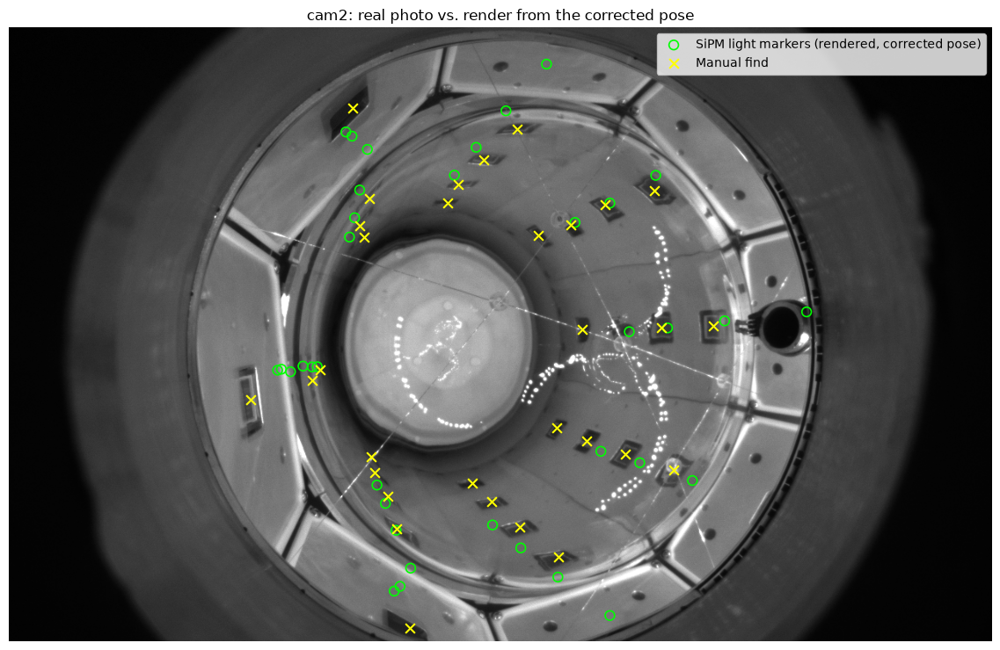

In [14]:
correctedLit, correctedBaseline = lc.render_light_marker_pair(camera, positions["sipm"],
                                                              toWorld=correctedToWorld)
save_render(correctedLit, f"cam{camera}_corrected_pose/all_sipms_lit")
save_render(correctedBaseline, f"cam{camera}_corrected_pose/baseline_no_markers")
correctedDetected = lc.detect_light_markers(correctedLit, baseline=correctedBaseline)
# Cached so the lens section below can compare against it without re-rendering.
correctedDetectedPath = f"outputs/pose_calibration/cam{camera}_rotation_only_detected.json"
with open(correctedDetectedPath, "w") as f:
    json.dump(correctedDetected.tolist(), f)

matchedClicks = clickedPixels[[o for _, o in poseFit["pairs"]]]
renderedResidual = np.array([np.linalg.norm(correctedDetected - c, axis=1).min() for c in matchedClicks])
assumedResidual = np.array([np.linalg.norm(detectedPixels - c, axis=1).min() for c in matchedClicks])
print(f"{len(correctedDetected)} light markers visible from the corrected pose")
print(f"matched clicks -> nearest rendered marker: assumed pose median {np.median(assumedResidual):.1f}px, "
      f"corrected pose median {np.median(renderedResidual):.1f}px (max {renderedResidual.max():.1f}px)")

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(correctedDetected[:, 0], correctedDetected[:, 1], s=60, facecolors='none',
           edgecolors='lime', linewidths=1.2, label='SiPM light markers (rendered, corrected pose)')
ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
           linewidths=1.5, label='Manual find')
ax.legend(loc='upper right')
ax.set_title(f"cam{camera}: real photo vs. render from the corrected pose")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"09_cam{camera}_real_photo_vs_corrected_render")

correctedPosePath = f"outputs/pose_calibration/cam{camera}_corrected_to_world.npy"
np.save(correctedPosePath, correctedToWorld)
print(f"saved corrected to_world to {correctedPosePath}")
np.save(poseSolveDir / f"cam{camera}_corrected_to_world.npy", correctedToWorld)

In [15]:
# Everything this run saved, as a tree.
def print_tree(root, indent=""):
    entries = sorted(root.iterdir(), key=lambda p: (p.is_file(), p.name))
    for k, entry in enumerate(entries):
        branch = "└── " if k == len(entries) - 1 else "├── "
        print(indent + branch + entry.name + ("/" if entry.is_dir() else ""))
        if entry.is_dir():
            print_tree(entry, indent + ("    " if k == len(entries) - 1 else "│   "))

print(f"{poseSolveDir}/")
print_tree(poseSolveDir)

outputs/poseSolve/2026_11_16_10_15_26/
├── figures/
│   ├── 01_cam2_assumed_pose_all_sipms_lit.png
│   ├── 02_cam2_assumed_pose_baseline.png
│   ├── 03_cam2_detected_light_markers.png
│   ├── 04_cam2_real_photo_vs_assumed_render.png
│   ├── 05_cam2_single_sipm_46_example.png
│   ├── 06_cam2_clicks_nearest_neighbor_matches.png
│   ├── 07_cam2_click_offsets_assumed_pose.png
│   ├── 08_cam2_corrected_pose_prediction.png
│   └── 09_cam2_real_photo_vs_corrected_render.png
├── renders/
│   ├── cam2_assumed_pose/
│   │   ├── single_sipm/
│   │   │   ├── sipm_46.png
│   │   │   └── sipm_46_diff.png
│   │   ├── all_sipms_lit.png
│   │   └── baseline_no_markers.png
│   └── cam2_corrected_pose/
│       ├── all_sipms_lit.png
│       └── baseline_no_markers.png
└── cam2_corrected_to_world.npy


## Focal length (fov) and lens distortion

The ~15px left over after the rotation fix grows toward the image edges, so the real
*lens* differs from the renders' perfect fov=86 pinhole. A real lens maps a point to a
pixel in three steps -- (1) the pinhole direction x = X/Z, y = Y/Z, (2) lens distortion
bends that, (3) the focal length (fov) scales it to pixels -- and
`lc.apply_radial_distortion()` follows that same order (OpenCV's convention).

Solving order here is by size of effect, biggest first:

1. **FOV solve** -- rotation + focal length. A pinhole at another fov is *exactly* a zoomed
   copy of the fov=86 render (refraction happens in the scene, not the sensor), and
   Mitsuba renders any fov natively, so this one needs no approximation or warp.
2. **Distortion on top** -- with the fov held at its solved value, fit only the radial
   distortion `k1` (negative = barrel). Mitsuba 3 has no distorting camera, so that part is
   applied by warping the native solved-fov render (`lc.distort_render()`, a `cv2.remap`).
3. **Side note** -- all four combinations fitted together, showing why the fov goes first:
   on its own, `k1` tries to do the fov's job and comes out unphysically strong.

**This section runs on its own**, even on a fresh kernel: the next cell loads everything
it needs from disk (CSV, clicked points, the cached per-SiPM render positions, the real
photo). Select it and use *Run -> Run Selected Cell and All Below* -- a few minutes (two
check renders) instead of re-running the whole notebook.

In [16]:
# Standalone setup for the lens section -- everything from disk, no renders.
import os, sys, json, functools, importlib
if not os.path.isdir("modules"):
    os.chdir("..")
if "modules" not in sys.path:
    sys.path.insert(0, "modules")
from utils import *
import pose_calibration as lc
import real_data_loading as rdl
importlib.reload(lc)  # picks up module edits without restarting the kernel
mi.set_log_level(mi.LogLevel.Error)

if "poseSolveDir" not in globals():  # fresh kernel: start a new run folder
    poseSolveDir = lc.new_run_dir()
    print("saving this run's images to", poseSolveDir)
save_figure = functools.partial(lc.save_figure, runDir=poseSolveDir)
save_render = functools.partial(lc.save_render, runDir=poseSolveDir)

camera = 2
run_name, frame = "20251114_37", 16
run_dir = rdl.RUN_DIRS[run_name]
ev = rdl.single_bubble_events(run_dir)[0]
realImage = load_image(rdl.camera_image_path(run_dir, ev, camera, frame))

positions = lc.load_sipm_fiducial_positions()
clickedPixels = lc.load_clicked_points(f"outputs/clicked_points/cam{camera}-img{frame}_sorted.json")
with open(f"outputs/pose_calibration/cam{camera}_sipm_render_positions.json") as f:
    sipmRenderPositions = {sid: np.array(xy) for sid, xy in json.load(f).items()}
sipmIds = list(sipmRenderPositions.keys())
assumedToWorld = np.array(create_sensor(sensor_number=camera)["to_world"].matrix)

# The rotation-only check render's detections (cell above), if it's been run since
# they started being cached -- only used for a side-by-side comparison.
correctedDetectedPath = f"outputs/pose_calibration/cam{camera}_rotation_only_detected.json"
if os.path.exists(correctedDetectedPath):
    with open(correctedDetectedPath) as f:
        correctedDetected = np.array(json.load(f))
else:
    correctedDetected = None
    print(f"no {correctedDetectedPath} yet -- skipping the rotation-only comparison "
          f"(run the rotation-only check render above once to create it)")

worldXYZ = [positions["sipm"][sid] for sid in sipmIds]
renderXY = [sipmRenderPositions[sid] for sid in sipmIds]

def fov_from_scale(focalScale, assumedFov=86):
    """fit_pose_correction()'s focalScale -> the equivalent fov in degrees."""
    return np.rad2deg(2 * np.arctan(np.tan(np.deg2rad(assumedFov / 2)) / focalScale))

print(f"loaded {len(positions['sipm'])} SiPM positions, {len(clickedPixels)} clicks, "
      f"{len(sipmIds)} cached render positions for cam{camera}")

loaded 48 SiPM positions, 31 clicks, 36 cached render positions for cam2


### 1. FOV solve

Rotation + `focalScale` only (no distortion), turned into the equivalent fov, with a
leave-one-click-out stability check. Then the next cell renders **natively at the solved
fov** with the corrected pose -- Mitsuba's own pinhole at that fov is exactly the view the
fit describes, image edges (outer SiPM panels) included.

In [17]:
fovFit = lc.fit_pose_correction(worldXYZ, renderXY, clickedPixels, assumedToWorld,
                                freeParams=lc.ROTATION_AND_FOCAL)
solvedFov = fov_from_scale(fovFit["distortion"]["focalScale"])
fovRotationDeg = np.rad2deg(fovFit["correction"][:3])

# Stability: re-solve once per matched click with that click left out.
looFovs, looRots = [], []
for _, obsIdx in fovFit["pairs"]:
    loo = lc.fit_pose_correction(worldXYZ, renderXY, np.delete(clickedPixels, obsIdx, axis=0),
                                 assumedToWorld, freeParams=lc.ROTATION_AND_FOCAL)
    looFovs.append(fov_from_scale(loo["distortion"]["focalScale"]))
    looRots.append(np.rad2deg(loo["correction"][:3]))

print(f"cam{camera} solved fov: {solvedFov:.2f} deg (assumed 86); leave-one-out range "
      f"{min(looFovs):.2f}-{max(looFovs):.2f} deg")
print(f"rotation correction: {fovRotationDeg.round(2)} deg, "
      f"{np.linalg.norm(fovRotationDeg):.2f} deg total (leave-one-out spread "
      f"{np.ptp(np.array(looRots), axis=0).round(2)} deg)")
print(f"{len(fovFit['pairs'])}/{len(clickedPixels)} clicks matched, predicted median "
      f"{np.median(fovFit['residualsPx']):.1f}px, max {fovFit['residualsPx'].max():.1f}px")

fovFitRecord = {
    "solvedFovDeg": solvedFov,
    "leaveOneOutFovRangeDeg": [min(looFovs), max(looFovs)],
    "rotationDeg": fovRotationDeg.tolist(),
    "matchedSipmIds": sorted(sipmIds[p] for p, _ in fovFit["pairs"]),
    "predictedMedianResidualPx": float(np.median(fovFit["residualsPx"])),
}

cam2 solved fov: 99.37 deg (assumed 86); leave-one-out range 98.63-99.47 deg
rotation correction: [-1.21  2.04  7.12] deg, 7.50 deg total (leave-one-out spread [0.36 0.16 0.73] deg)
27/31 clicks matched, predicted median 6.9px, max 30.0px


saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_fov_solve_pose/all_sipms_lit_fov99.4.png


saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_fov_solve_pose/baseline_no_markers_fov99.4.png
38 light markers in the native fov=99.4 render
27 matched clicks -> nearest rendered marker: median 9.3px, max 19.4px
all 31 clicks (incl. unmatched) -> nearest marker: median 10.5px; clicks still >30px off: [0, 1, 2]
  vs. rotation-only fov=86 render, same clicks: median 20.3px


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/10_cam2_real_vs_native_fov_render.png


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/11_cam2_native_fov_markers_vs_clicks.png
saved FOV solve to outputs/poseSolve/2026_11_16_10_15_26/cam2_fov_fit.json (render with create_sensor(fov=solvedFovDeg, to_world=...fov_fit_to_world.npy))


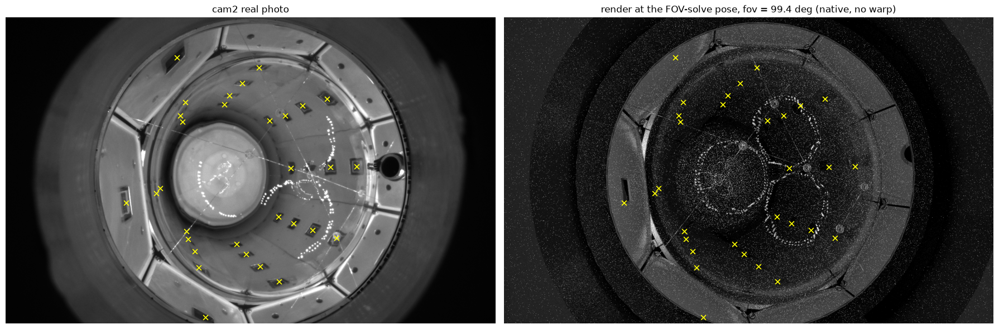

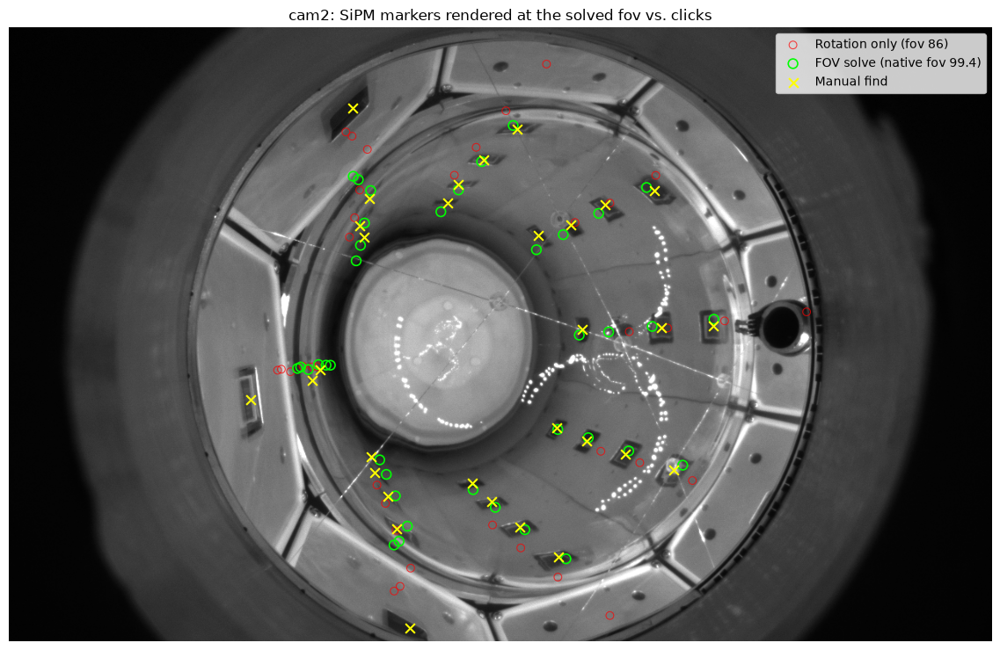

In [18]:
# Native render at the solved fov (no warp) -- the real check of the FOV solve.
fovLit, fovBaseline = lc.render_light_marker_pair(camera, positions["sipm"], toWorld=fovFit["toWorld"],
                                                  fov=solvedFov)
fovDetected = lc.detect_light_markers(fovLit, baseline=fovBaseline)
save_render(fovLit, f"cam{camera}_fov_solve_pose/all_sipms_lit_fov{solvedFov:.1f}")
save_render(fovBaseline, f"cam{camera}_fov_solve_pose/baseline_no_markers_fov{solvedFov:.1f}")

fovMatchedClicks = clickedPixels[[o for _, o in fovFit["pairs"]]]
fovResidual = np.array([np.linalg.norm(fovDetected - c, axis=1).min() for c in fovMatchedClicks])
allClicksResidual = np.array([np.linalg.norm(fovDetected - c, axis=1).min() for c in clickedPixels])
print(f"{len(fovDetected)} light markers in the native fov={solvedFov:.1f} render")
print(f"{len(fovMatchedClicks)} matched clicks -> nearest rendered marker: median {np.median(fovResidual):.1f}px, "
      f"max {fovResidual.max():.1f}px")
print(f"all {len(clickedPixels)} clicks (incl. unmatched) -> nearest marker: median "
      f"{np.median(allClicksResidual):.1f}px; clicks still >30px off: "
      f"{np.flatnonzero(allClicksResidual > 30).tolist()}")
if correctedDetected is not None:
    rotationOnlyResidual = np.array([np.linalg.norm(correctedDetected - c, axis=1).min() for c in fovMatchedClicks])
    print(f"  vs. rotation-only fov=86 render, same clicks: median {np.median(rotationOnlyResidual):.1f}px")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].imshow(realImage, cmap='gray')
axes[0].set_title(f"cam{camera} real photo")
axes[1].imshow(np.clip(fovBaseline, 0, 1) ** (1 / 2.2), cmap='gray')
axes[1].set_title(f"render at the FOV-solve pose, fov = {solvedFov:.1f} deg (native, no warp)")
for ax in axes:
    ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=40, marker='x', color='yellow', linewidths=1.2)
    ax.axis('off')
fig.tight_layout()
save_figure(fig, f"10_cam{camera}_real_vs_native_fov_render")

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
if correctedDetected is not None:
    ax.scatter(correctedDetected[:, 0], correctedDetected[:, 1], s=40, facecolors='none',
               edgecolors='red', linewidths=0.8, alpha=0.7, label='Rotation only (fov 86)')
ax.scatter(fovDetected[:, 0], fovDetected[:, 1], s=60, facecolors='none', edgecolors='lime',
           linewidths=1.2, label=f'FOV solve (native fov {solvedFov:.1f})')
ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
           linewidths=1.5, label='Manual find')
ax.legend(loc='upper right')
ax.set_title(f"cam{camera}: SiPM markers rendered at the solved fov vs. clicks")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"11_cam{camera}_native_fov_markers_vs_clicks")

fovFitRecord["renderedMedianResidualPx"] = float(np.median(fovResidual))
for fovFitPath in [poseSolveDir / f"cam{camera}_fov_fit.json",
                   pathlib.Path(f"outputs/pose_calibration/cam{camera}_fov_fit.json")]:
    fovFitPath.parent.mkdir(parents=True, exist_ok=True)
    with open(fovFitPath, "w") as f:
        json.dump(fovFitRecord, f, indent=1)
np.save(poseSolveDir / f"cam{camera}_fov_fit_to_world.npy", fovFit["toWorld"])
np.save(f"outputs/pose_calibration/cam{camera}_fov_fit_to_world.npy", fovFit["toWorld"])
print("saved FOV solve to", poseSolveDir / f"cam{camera}_fov_fit.json",
      "(render with create_sensor(fov=solvedFovDeg, to_world=...fov_fit_to_world.npy))")

### 2. Distortion on top of the solved fov

Starting from the FOV solve, hold the fov fixed and free `k1` (plus the rotation, so it can
re-balance slightly). If `k1` comes out small, stable when clicks are left out, and
physical (`lc.distortion_is_monotonic()` -- the model must not fold back on itself before
the image corner), the warp below applies it to the native solved-fov render; since it's a
small correction, the warp barely shrinks the image.

In [19]:
k1Fit = lc.fit_pose_correction(worldXYZ, renderXY, clickedPixels, assumedToWorld,
                               freeParams=lc.ROTATION_AND_K1, initialCorrection=fovFit["correction"])
fittedK1 = k1Fit["distortion"]["k1"]
assert abs(k1Fit["distortion"]["focalScale"] - fovFit["distortion"]["focalScale"]) < 1e-12  # fov held fixed

looK1 = []
for _, obsIdx in k1Fit["pairs"]:
    loo = lc.fit_pose_correction(worldXYZ, renderXY, np.delete(clickedPixels, obsIdx, axis=0), assumedToWorld,
                                 freeParams=lc.ROTATION_AND_K1, initialCorrection=fovFit["correction"])
    looK1.append(loo["distortion"]["k1"])

k1Monotonic = lc.distortion_is_monotonic(fittedK1, fov=solvedFov)
print(f"k1 on top of fov {solvedFov:.2f} deg: {fittedK1:.3f} (leave-one-out range "
      f"{min(looK1):.3f} to {max(looK1):.3f}); physical (no fold-back): {k1Monotonic}")
print(f"rotation: {np.rad2deg(k1Fit['correction'][:3]).round(2)} deg "
      f"(FOV solve alone: {fovRotationDeg.round(2)} deg)")
print(f"{len(k1Fit['pairs'])}/{len(clickedPixels)} clicks matched, predicted median "
      f"{np.median(k1Fit['residualsPx']):.1f}px (FOV solve alone: {np.median(fovFit['residualsPx']):.1f}px)")

k1 on top of fov 99.37 deg: -0.065 (leave-one-out range -0.075 to 0.023); physical (no fold-back): True
rotation: [-1.25  2.17  7.11] deg (FOV solve alone: [-1.21  2.04  7.12] deg)
28/31 clicks matched, predicted median 8.8px (FOV solve alone: 6.9px)


saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_fov_k1_pose/all_sipms_lit_fov99.4_unwarped.png


saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_fov_k1_pose/all_sipms_lit_fov99.4_k1warped.png


saved render: outputs/poseSolve/2026_11_16_10_15_26/renders/cam2_fov_k1_pose/baseline_no_markers_fov99.4_k1warped.png
38 light markers in the k1-warped render
28 matched clicks -> nearest rendered marker: fov + k1 median 10.0px (max 19.9px) vs. fov only 9.8px (max 19.4px)


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/12_cam2_real_vs_fov_k1_render.png


saved figure: outputs/poseSolve/2026_11_16_10_15_26/figures/13_cam2_fov_k1_markers_vs_clicks.png
saved lens fit to outputs/poseSolve/2026_11_16_10_15_26/cam2_lens_fit.json


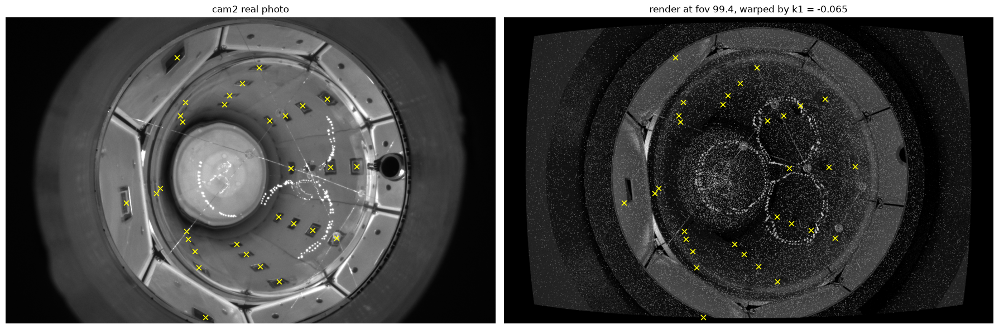

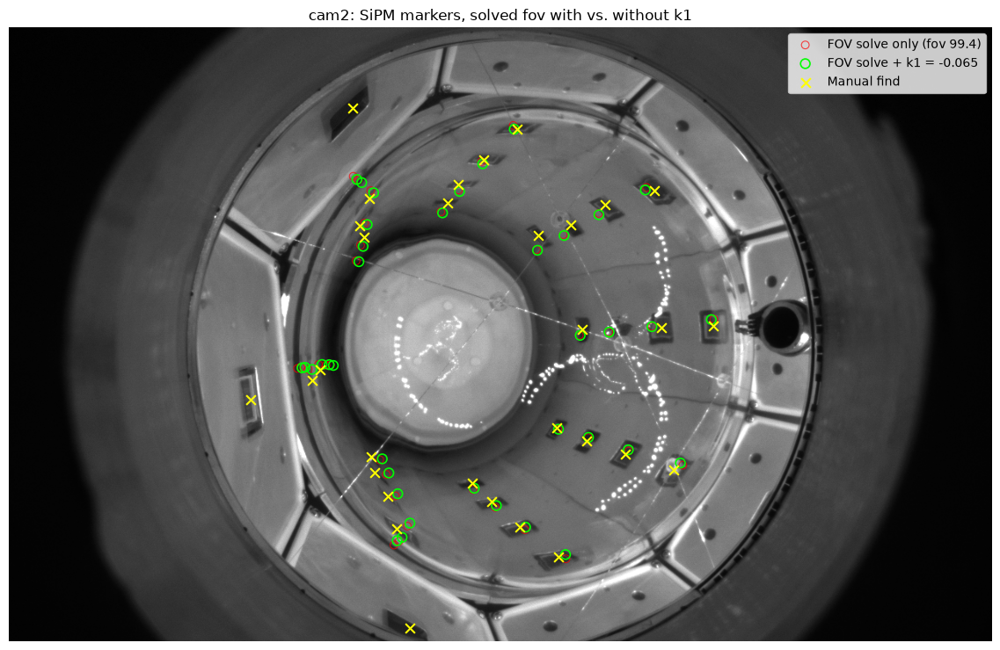

In [20]:
# Check with a real render: native render at the solved fov from the k1 fit's pose, then
# warp it by k1 alone. The warp's camera matrix is the solved-fov one, so k1 acts on the
# same normalized coordinates the fit used.
solvedCameraMatrix = get_ideal_camera_matrix(solvedFov)
k1Lit, k1Baseline = lc.render_light_marker_pair(camera, positions["sipm"], toWorld=k1Fit["toWorld"],
                                                fov=solvedFov)
warpedLit = lc.distort_render(k1Lit, fittedK1, cameraMatrix=solvedCameraMatrix)
warpedBaseline = lc.distort_render(k1Baseline, fittedK1, cameraMatrix=solvedCameraMatrix)
warpedDetected = lc.detect_light_markers(warpedLit, baseline=warpedBaseline)
save_render(k1Lit, f"cam{camera}_fov_k1_pose/all_sipms_lit_fov{solvedFov:.1f}_unwarped")
save_render(warpedLit, f"cam{camera}_fov_k1_pose/all_sipms_lit_fov{solvedFov:.1f}_k1warped")
save_render(warpedBaseline, f"cam{camera}_fov_k1_pose/baseline_no_markers_fov{solvedFov:.1f}_k1warped")

k1MatchedClicks = clickedPixels[[o for _, o in k1Fit["pairs"]]]
warpedResidual = np.array([np.linalg.norm(warpedDetected - c, axis=1).min() for c in k1MatchedClicks])
fovOnlyResidual = np.array([np.linalg.norm(fovDetected - c, axis=1).min() for c in k1MatchedClicks])
print(f"{len(warpedDetected)} light markers in the k1-warped render")
print(f"{len(k1MatchedClicks)} matched clicks -> nearest rendered marker: fov + k1 median "
      f"{np.median(warpedResidual):.1f}px (max {warpedResidual.max():.1f}px) vs. fov only "
      f"{np.median(fovOnlyResidual):.1f}px (max {fovOnlyResidual.max():.1f}px)")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].imshow(realImage, cmap='gray')
axes[0].set_title(f"cam{camera} real photo")
axes[1].imshow(np.clip(warpedBaseline, 0, 1) ** (1 / 2.2), cmap='gray')
axes[1].set_title(f"render at fov {solvedFov:.1f}, warped by k1 = {fittedK1:.3f}")
for ax in axes:
    ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=40, marker='x', color='yellow', linewidths=1.2)
    ax.axis('off')
fig.tight_layout()
save_figure(fig, f"12_cam{camera}_real_vs_fov_k1_render")

fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(realImage, cmap='gray')
ax.scatter(fovDetected[:, 0], fovDetected[:, 1], s=40, facecolors='none', edgecolors='red',
           linewidths=0.8, alpha=0.7, label=f'FOV solve only (fov {solvedFov:.1f})')
ax.scatter(warpedDetected[:, 0], warpedDetected[:, 1], s=60, facecolors='none', edgecolors='lime',
           linewidths=1.2, label=f'FOV solve + k1 = {fittedK1:.3f}')
ax.scatter(clickedPixels[:, 0], clickedPixels[:, 1], s=60, marker='x', color='yellow',
           linewidths=1.5, label='Manual find')
ax.legend(loc='upper right')
ax.set_title(f"cam{camera}: SiPM markers, solved fov with vs. without k1")
ax.axis('off')
fig.tight_layout()
save_figure(fig, f"13_cam{camera}_fov_k1_markers_vs_clicks")

lensFitRecord = {
    **fovFitRecord,
    "k1": fittedK1,
    "k1LeaveOneOutRange": [min(looK1), max(looK1)],
    "k1Physical": k1Monotonic,
    "rotationDegWithK1": np.rad2deg(k1Fit["correction"][:3]).tolist(),
    "renderedMedianResidualPxWithK1": float(np.median(warpedResidual)),
    "renderedMedianResidualPxFovOnly": float(np.median(fovOnlyResidual)),
}
for lensFitPath in [poseSolveDir / f"cam{camera}_lens_fit.json",
                    pathlib.Path(f"outputs/pose_calibration/cam{camera}_lens_fit.json")]:
    with open(lensFitPath, "w") as f:
        json.dump(lensFitRecord, f, indent=1)
np.save(poseSolveDir / f"cam{camera}_fov_k1_fit_to_world.npy", k1Fit["toWorld"])
print("saved lens fit to", poseSolveDir / f"cam{camera}_lens_fit.json")

### 3. Side note: why the fov goes first

All four combinations fitted from scratch against the fov=86 starting point, each with a
leave-one-click-out stability check. With the fov held at 86, `k1` alone has to fake a
zoom and comes out far too strong (it folds the image back on itself); with the fov free,
`k1` adds little and isn't pinned down by the data.

In [21]:
lensVariants = {
    "rotation only": lc.ROTATION_ONLY,
    "rotation + k1": lc.ROTATION_AND_K1,
    "rotation + focal": lc.ROTATION_AND_FOCAL,
    "rotation + focal + k1": lc.ROTATION_FOCAL_AND_K1,
}
lensFits = {}
print(f"{'variant':22s} {'rotation (deg)':22s} {'k1':>7s} {'fov':>6s} {'matches':>7s} {'median':>7s} {'max':>6s}  "
      f"leave-one-out spread")
for name, freeParams in lensVariants.items():
    fit = lc.fit_pose_correction(worldXYZ, renderXY, clickedPixels, assumedToWorld, freeParams=freeParams)
    lensFits[name] = fit
    dist = fit["distortion"]

    looK1, looScale, looRot = [], [], []
    for _, obsIdx in fit["pairs"]:
        loo = lc.fit_pose_correction(worldXYZ, renderXY, np.delete(clickedPixels, obsIdx, axis=0),
                                     assumedToWorld, freeParams=freeParams)
        looK1.append(loo["distortion"]["k1"])
        looScale.append(loo["distortion"]["focalScale"])
        looRot.append(np.rad2deg(loo["correction"][:3]))
    rotSpread = np.ptp(np.array(looRot), axis=0).max()

    folds = "" if lc.distortion_is_monotonic(dist["k1"]) else " (folds!)"
    print(f"{name:22s} {str(np.rad2deg(fit['correction'][:3]).round(2)):22s} {dist['k1']:7.3f} "
          f"{fov_from_scale(dist['focalScale']):6.1f} {len(fit['pairs']):7d} "
          f"{np.median(fit['residualsPx']):6.1f}px {fit['residualsPx'].max():5.1f}px  "
          f"rot {rotSpread:.2f}deg, k1 {np.ptp(looK1):.3f}, fov {np.ptp([fov_from_scale(s) for s in looScale]):.1f}deg"
          f"{folds}")

variant                rotation (deg)              k1    fov matches  median    max  leave-one-out spread


rotation only          [-0.93  5.1   6.73]      0.000   86.0      23   18.6px  29.5px  rot 0.92deg, k1 0.000, fov 0.0deg


rotation + k1          [-0.93  1.98  6.2 ]     -0.918   86.0      28   15.6px  28.3px  rot 0.84deg, k1 0.070, fov 0.0deg (folds!)


rotation + focal       [-1.21  2.04  7.12]      0.000   99.4      27    6.9px  30.0px  rot 0.73deg, k1 0.000, fov 0.8deg


rotation + focal + k1  [-1.29  1.98  7.11]     -0.381   94.7      28    8.2px  33.4px  rot 0.94deg, k1 0.172, fov 1.7deg (folds!)


## Next steps (TODO)

- [ ] **Lens distortion correction:** The remaining ~15 px error grows toward the edges of the image, which looks like lens distortion. Mitsuba 3 has no distorting camera, so the plan is to keep rendering with the normal pinhole camera and then warp each render with `cv2.remap` using a radial distortion model (`k1`, possibly `k2`) so it matches the raw photo. First fit `k1` together with the rotation against the clicked covers, using the cached per-SiPM data. Then check that the warped render lines up better with the real photo. Since barrel distortion pulls the edges inward, the render needs a slightly wider fov so the warped corners aren't empty.

- [ ] **Position movement:** When the camera position was allowed to change, the fit moved it 2-3 cm into the CAD viewport, which isn't physical. Most likely the translation was making up for the missing lens distortion. Once distortion is in the model, try freeing x, y, z again, limited to a few millimetres. A render at the result has to show the camera still sitting behind the viewport with all SiPMs visible. If the position barely moves, that confirms the designed mount position is correct.

- [ ] **Camera 1 and 3 pose:** Camera 2 is done; cameras 1 and 3 still need their SiPM covers clicked with `scripts/click_label_points.py` on the same event and frame. After that, each needs a single ~15-minute pass rendering each SiPM on its own (cached afterwards), then the same rotation (and distortion) fit and check render. Comparing all three corrections will show whether there's a shared error (e.g. the whole camera mount plate being rotated) or each camera is off on its own.

- [ ] **Rerun with some SiPMs removed:** Re-fit leaving out one SiPM at a time (and the worst few as a group) to check that the ~8 deg rotation isn't driven by a few bad clicks or mismatches. If the rotation stays within a fraction of a degree, the result is solid. If removing certain SiPMs gives a clearly better fit, those clicks or their positions in the CSV are worth rechecking.

- [ ] **Rerun previous rendering work with the new pose:** This is the real test of whether the calibration matters. Rerun `RealDataRenderComparison.ipynb` with the corrected `to_world` (plus the distortion warp, once it exists) and check whether the rendered bubbles line up better with the real frames. Any triangulation that uses the camera poses should also be redone, to see how much the bubble positions change.